# Análise de Tempo de Entrega — Food Delivery Dataset

**Objetivo:** entender o que realmente determina o tempo de entrega de um app de delivery e transformar isso em recomendações operacionais.

**Dataset:** [Food Delivery Dataset — Gaurav Malik (Kaggle)](https://www.kaggle.com/datasets/gauravmalik26/food-delivery-dataset) · 45.593 pedidos · 20 colunas · 22 cidades da Índia · fev–abr/2022.

### Perguntas de negócio
1. Qual é o tempo típico de entrega e quantos pedidos estouram uma promessa de 30 minutos?
2. Quais fatores operacionais (trânsito, distância, entregas agrupadas) mais pesam?
3. Fatores externos (clima, festivais) importam? Quanto?
4. A frota e o perfil do entregador influenciam o resultado?
5. Qual é o efeito de cada fator quando os demais são mantidos constantes?

### Roteiro
1. Diagnóstico da base bruta
2. Limpeza e engenharia de atributos
3. Visão geral e SLA
4. Fatores operacionais
5. Fatores externos
6. Frota
7. Entregadores
8. Geografia
9. Testes estatísticos
10. Análise multivariada (efeito isolado de cada fator)
11. Conclusões, recomendações e limitações

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

sys.path.append(str(Path("src").resolve()))
from limpeza import carregar_bruto, limpar, ORDEM_TRANSITO
from graficos import aplicar_estilo, salvar, rotular_barras, AZUL, LARANJA, CINZA, RAMPA_AZUL, TEXTO_2

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.2f}".format)
aplicar_estilo()

ALVO = "tempo_entrega_min"
SLA_MIN = 30

## 1. Diagnóstico da base bruta

Antes de limpar, é preciso entender **como** a base está suja. Tudo é lido como texto para não esconder problemas atrás de conversões automáticas.

In [2]:
bruto = carregar_bruto("data/raw/food_delivery.csv")
print(bruto.shape)
bruto.head()

(45593, 20)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.6784,12.924264,77.6884,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [3]:
def perfil(df):
    linhas = []
    for c in df.columns:
        s = df[c]
        linhas.append({
            "coluna": c,
            "nulos_reais": s.isna().sum(),
            "texto_'NaN'": (s.str.strip() == "NaN").sum(),
            "com_espaço_extra": (s != s.str.strip()).sum(),
            "valores_únicos": s.str.strip().nunique(),
            "exemplo": s.iloc[0],
        })
    return pd.DataFrame(linhas)

perfil(bruto)

,coluna,nulos_reais,texto_'NaN',com_espaço_extra,valores_únicos,exemplo
0,ID,0,0,45593,45593,0x4607
1,Delivery_person_ID,0,0,45593,1320,INDORES13DEL02
2,Delivery_person_Age,0,1854,1854,23,37
3,Delivery_person_Ratings,0,1908,1908,29,4.9
4,Restaurant_latitude,0,0,0,658,22.745049
5,Restaurant_longitude,0,0,0,519,75.892471
6,Delivery_location_latitude,0,0,0,4373,22.765049
7,Delivery_location_longitude,0,0,0,4373,75.912471
8,Order_Date,0,0,0,44,19-03-2022
9,Time_Orderd,0,1731,1731,177,11:30:00


In [4]:
for c in ["Delivery_person_Age", "Delivery_person_Ratings"]:
    print(c, "->", sorted(bruto[c].str.strip().unique(), key=lambda v: (v == "NaN", float(v) if v != "NaN" else 0)))

print("\nLatitudes negativas no restaurante:", (bruto["Restaurant_latitude"].astype(float) < 0).sum())
print("Restaurantes com coordenada 0:", (bruto["Restaurant_latitude"].astype(float).abs() < 1).sum())
print("Valores do alvo:", bruto["Time_taken(min)"].head(3).tolist())

Delivery_person_Age -> ['15', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '50', 'NaN']
Delivery_person_Ratings -> ['1', '2.5', '2.6', '2.7', '2.8', '2.9', '3', '3.1', '3.2', '3.3', '3.4', '3.5', '3.6', '3.7', '3.8', '3.9', '4', '4.1', '4.2', '4.3', '4.4', '4.5', '4.6', '4.7', '4.8', '4.9', '5', '6', 'NaN']

Latitudes negativas no restaurante: 431
Restaurantes com coordenada 0: 3640
Valores do alvo: ['(min) 24', '(min) 33', '(min) 26']


### Problemas encontrados

| # | Problema | Exemplo | Tratamento |
|---|----------|---------|------------|
| 1 | Nulos gravados como texto | `"NaN "` | Converter para `NaN` real |
| 2 | Espaços extras em quase todas as colunas texto | `"Snack "` | `str.strip()` |
| 3 | Alvo com prefixo textual | `"(min) 24"` | Extrair número com regex |
| 4 | Clima com prefixo | `"conditions Sunny"` | Remover prefixo |
| 5 | Números armazenados como texto | idade, nota, entregas | `to_numeric` |
| 6 | Nota **6** numa escala de 1 a 5 e idade **15** | 91 registros | Investigar (abaixo) |
| 7 | Latitudes negativas (a Índia fica no hemisfério norte) | `-15.30` | Valor absoluto |
| 8 | Coordenadas zeradas | `0.0, 0.0` | Marcar como ausente |
| 9 | Pedidos que atravessam a meia-noite | pedido 23:55, coleta 00:05 | Somar 1 dia à coleta |
| 10 | Cidade real só existe dentro do ID do entregador | `INDORES13DEL02` | Extrair `INDO` |

### Os registros com nota 6 e idade 15

In [5]:
idade = bruto["Delivery_person_Age"].str.strip()
nota = bruto["Delivery_person_Ratings"].str.strip()
pd.crosstab(idade.isin(["15", "50"]).rename("idade 15 ou 50"), nota.isin(["1", "6"]).rename("nota 1 ou 6"))

nota 1 ou 6,False,True
idade 15 ou 50,,
False,45502,0
True,0,91


As 91 linhas com idade 15/50 são **exatamente** as 91 com nota 1/6 — e sempre nos mesmos pares (idade 50 ↔ nota 6, idade 15 ↔ nota 1).
Isso não é ruído aleatório: são **perfis de teste/placeholder** do sistema. Nota 6 é impossível e idade 15 é abaixo da idade legal; removemos os 91 registros (0,2% da base).

## 2. Limpeza e engenharia de atributos

Toda a lógica está em `src/limpeza.py` (funções pequenas e testáveis). Atributos criados: `distancia_km` (Haversine), `tempo_preparo_min`, `hora_do_dia`, `dia_semana`, `cidade`.

In [6]:
df, log = limpar(bruto)
print(log)
print(df.shape)
df.head()

{'perfis_teste_removidos': 91}
(45502, 27)


,id_pedido,id_entregador,idade_entregador,nota_entregador,rest_lat,rest_lon,dest_lat,dest_lon,data_pedido,hora_pedido,hora_coleta,clima,transito,condicao_veiculo,tipo_pedido,tipo_veiculo,entregas_multiplas,festival,tipo_cidade,tempo_entrega_min,ts_pedido,ts_coleta,tempo_preparo_min,hora_do_dia,dia_semana,distancia_km,cidade
0,0x4607,INDORES13DEL02,37.00,4.90,22.75,75.89,22.77,75.91,2022-03-19,11:30:00,11:45:00,Ensolarado,Alto,2,Lanche,Moto,0,Não,Urbana,24.00,2022-03-19 11:30:00,2022-03-19 11:45:00,15.00,11,5,3.03,INDO
1,0xb379,BANGRES18DEL02,34.00,4.50,12.91,77.68,13.04,77.81,2022-03-25,19:45:00,19:50:00,Tempestade,Congestionado,2,Lanche,Scooter,1,Não,Metropolitana,33.00,2022-03-25 19:45:00,2022-03-25 19:50:00,5.00,19,4,20.18,BANG
2,0x5d6d,BANGRES19DEL01,23.00,4.40,12.91,77.68,12.92,77.69,2022-03-19,08:30:00,08:45:00,Tempestade de areia,Baixo,0,Bebidas,Moto,1,Não,Urbana,26.00,2022-03-19 08:30:00,2022-03-19 08:45:00,15.00,8,5,1.55,BANG
3,0x7a6a,COIMBRES13DEL02,38.00,4.70,11.00,76.98,11.05,77.03,2022-04-05,18:00:00,18:10:00,Ensolarado,Médio,0,Buffet,Moto,1,Não,Metropolitana,21.00,2022-04-05 18:00:00,2022-04-05 18:10:00,10.00,18,1,7.79,COIMB
4,0x70a2,CHENRES12DEL01,32.00,4.60,12.97,80.25,13.01,80.29,2022-03-26,13:30:00,13:45:00,Nublado,Alto,1,Lanche,Scooter,1,Não,Metropolitana,30.00,2022-03-26 13:30:00,2022-03-26 13:45:00,15.00,13,5,6.21,CHEN


In [7]:
# Checagens de sanidade da base limpa
assert df["id_pedido"].is_unique
assert df[ALVO].notna().all() and df[ALVO].between(1, 120).all()
assert df["nota_entregador"].dropna().between(1, 5).all()
assert df["idade_entregador"].dropna().ge(18).all()
assert (df["tempo_preparo_min"].dropna() >= 0).all()
assert df["distancia_km"].dropna().lt(30).all()
print("Todas as checagens passaram")
df.dtypes

Todas as checagens passaram


id_pedido                        str
id_entregador                    str
idade_entregador             float64
nota_entregador              float64
rest_lat                     float64
rest_lon                     float64
dest_lat                     float64
dest_lon                     float64
data_pedido           datetime64[us]
hora_pedido                      str
hora_coleta                      str
clima                            str
transito                    category
condicao_veiculo               Int64
tipo_pedido                      str
tipo_veiculo                     str
entregas_multiplas             Int64
festival                         str
tipo_cidade                      str
tempo_entrega_min            float64
ts_pedido             datetime64[us]
ts_coleta             datetime64[us]
tempo_preparo_min            float64
hora_do_dia                    Int64
dia_semana                     int32
distancia_km                 float64
cidade                           str
d

### 2.1 Os valores ausentes são aleatórios?

In [8]:
ausentes = df.isna().mean().mul(100).round(2)
ausentes = ausentes[ausentes > 0].sort_values(ascending=False).to_frame("% ausente")
ausentes

,% ausente
rest_lon,7.98
rest_lat,7.98
dest_lon,7.98
dest_lat,7.98
distancia_km,7.98
nota_entregador,4.19
idade_entregador,4.07
hora_pedido,3.60
ts_pedido,3.60
hora_do_dia,3.60


In [9]:
cols_na = ["nota_entregador", "hora_pedido", "clima", "transito", "entregas_multiplas", "tipo_cidade"]
sem_idade = df["idade_entregador"].isna()
(df[cols_na].isna().groupby(sem_idade.rename("idade ausente")).mean() * 100).round(1).T

idade ausente,False,True
nota_entregador,0.10,100.00
hora_pedido,0.00,88.50
clima,0.00,28.30
transito,0.00,27.50
entregas_multiplas,2.10,3.20
tipo_cidade,2.60,3.30


**Achado:** os nulos **não são independentes**. Quando a idade do entregador falta, a nota falta em 100% dos casos, o horário do pedido em 88% e o clima/trânsito em ~28% (contra 0% nos demais).
Há um bloco de ~1,8 mil pedidos com **cadastro incompleto** — típico de falha de integração em uma origem específica.

Como o tempo médio desse bloco é praticamente igual ao do restante (veja abaixo), **não excluímos** essas linhas: cada análise usa os dados disponíveis para a variável em questão e o modelo final trata ausentes nativamente.

In [10]:
df.groupby(sem_idade.map({True: "cadastro incompleto", False: "completo"}))[ALVO].agg(["count", "mean", "median"])

,count,mean,median
idade_entregador,,,
cadastro incompleto,1854,26.46,25.00
completo,43648,26.29,26.00


In [11]:
df.to_csv("data/processed/food_delivery_limpo.csv", index=False)
print("Base limpa salva em data/processed/")

Base limpa salva em data/processed/


## 3. Visão geral e SLA de 30 minutos

In [12]:
resumo = df[ALVO].describe(percentiles=[.1, .25, .5, .75, .9, .95])
acima_sla = (df[ALVO] > SLA_MIN).mean()
print(resumo.round(1))
print(f"\nPedidos acima de {SLA_MIN} min: {acima_sla:.1%}")

count   45502.00
mean       26.30
std         9.40
min        10.00
10%        15.00
25%        19.00
50%        26.00
75%        32.00
90%        40.00
95%        44.00
max        54.00
Name: tempo_entrega_min, dtype: float64

Pedidos acima de 30 min: 29.9%


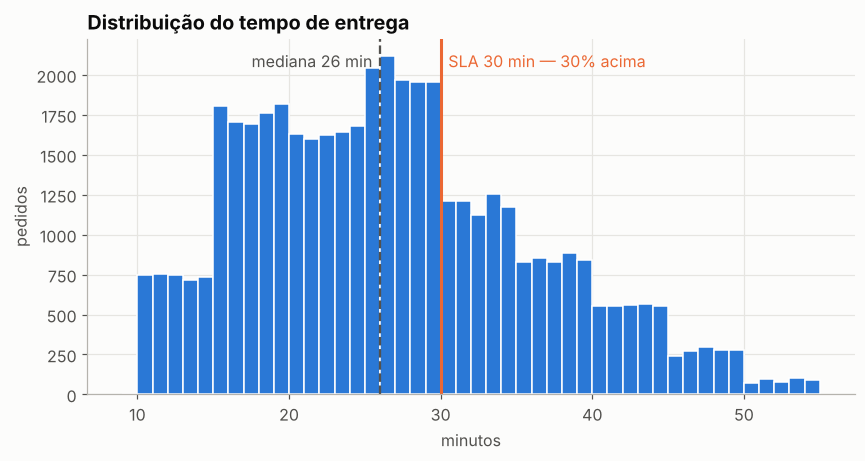

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hist(df[ALVO], bins=range(9, 56), color=AZUL, edgecolor="white", linewidth=1)
ax.axvline(df[ALVO].median(), color=TEXTO_2, ls="--", lw=1.5)
ax.axvline(SLA_MIN, color=LARANJA, lw=2)
ax.text(df[ALVO].median() - 0.5, ax.get_ylim()[1] * 0.92, f"mediana {df[ALVO].median():.0f} min", ha="right", color=TEXTO_2)
ax.text(SLA_MIN + 0.5, ax.get_ylim()[1] * 0.92, f"SLA {SLA_MIN} min — {acima_sla:.0%} acima", color=LARANJA)
ax.set_title("Distribuição do tempo de entrega")
ax.set_xlabel("minutos")
ax.set_ylabel("pedidos")
salvar(fig, "01_distribuicao")
plt.show()

A distribuição é **assimétrica à direita**: mediana de 26 min, mas 10% dos pedidos passam de 40 min e o máximo chega a 54 min. Note também os **degraus a cada 5 minutos** no histograma — um primeiro sinal de que a base foi gerada/arredondada por regra (ver Limitações).
**Quase 1 em cada 3 pedidos (29,9%) passa de 30 minutos.** A cauda acima de 40 min é o que destrói a experiência do cliente — o resto da análise busca descobrir quem a gera.

## 4. Fatores operacionais

### 4.1 Trânsito

,pedidos,media,mediana,pct_acima_sla
transito,,,,
Baixo,15477,21.30,20.00,7.90
Médio,10947,26.70,27.00,32.50
Alto,4425,27.20,27.00,33.60
Congestionado,14143,31.20,31.00,50.60


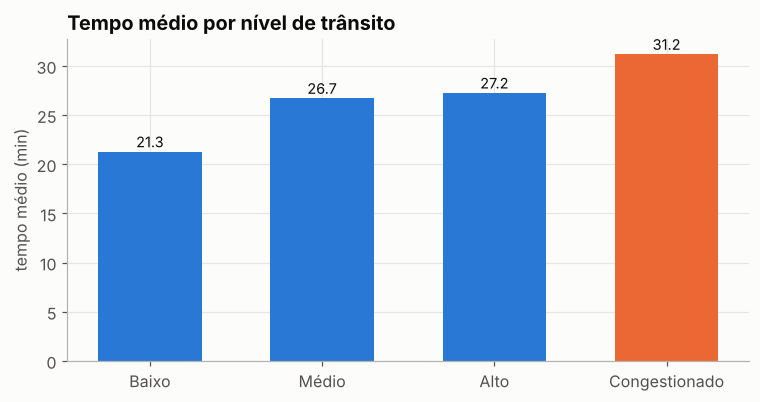

In [14]:
g = df.groupby("transito", observed=True)[ALVO].agg(pedidos="count", media="mean", mediana="median",
                                               pct_acima_sla=lambda s: (s > SLA_MIN).mean() * 100)
g = g.loc[['Baixo', 'Médio', 'Alto', 'Congestionado']]
display(g.round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
cores = [LARANJA if i == g.index.get_loc('Congestionado') else AZUL for i in range(len(g))]
ax.bar(g.index.astype(str), g['media'], color=cores, width=0.6)
rotular_barras(ax, horizontal=False)
ax.set_title("Tempo médio por nível de trânsito")
ax.set_ylabel('tempo médio (min)')

salvar(fig, "02_transito")
plt.show()

Do trânsito **baixo** para o **congestionado**, o tempo médio sobe de ~21 para ~31 min (**+47%**), e a fatia de pedidos fora do SLA salta de **8% para 51%**.
Curiosidade: "Médio" e "Alto" praticamente empatam.

### 4.2 Trânsito × hora do dia — um alerta de confusão

In [15]:
faixas = pd.cut(df["hora_do_dia"].astype(float), [-1, 5, 10, 14, 17, 20, 23],
                labels=["00–05", "06–10", "11–14", "15–17", "18–20", "21–23"])
tab = pd.crosstab(faixas, df["transito"], normalize="index").mul(100).round(0)
tab["tempo_medio"] = df.groupby(faixas, observed=True)[ALVO].mean().round(1)
tab["pedidos"] = faixas.value_counts()
tab

transito,Baixo,Médio,Alto,Congestionado,tempo_medio,pedidos
hora_do_dia,,,,,,
00–05,100.00,0.00,0.00,0.00,22.20,430
06–10,100.00,0.00,0.00,0.00,19.50,5756
11–14,4.00,0.00,96.00,0.00,26.90,4429
15–17,0.00,99.00,1.00,0.00,26.20,5860
18–20,0.00,36.00,0.00,64.00,29.80,13614
21–23,63.00,0.00,0.00,37.00,25.60,13773


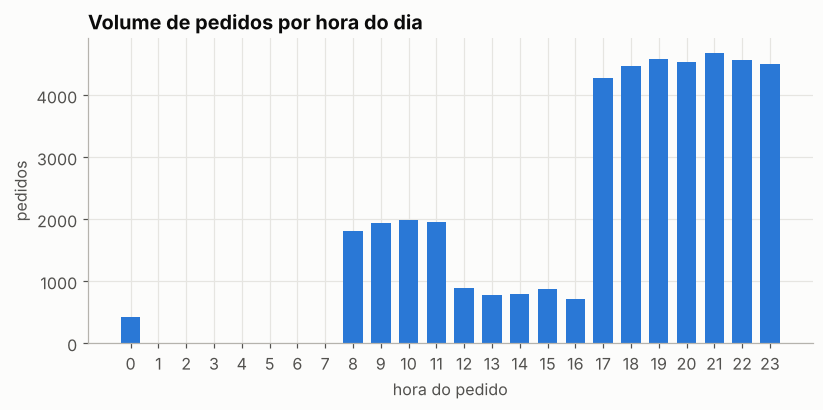

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
h = df.groupby("hora_do_dia")[ALVO].agg(["mean", "count"])
ax.bar(h.index.astype(int), h["count"], color=AZUL, width=0.7)
ax.set_title("Volume de pedidos por hora do dia")
ax.set_xlabel("hora do pedido")
ax.set_ylabel("pedidos")
ax.set_xticks(range(0, 24))
salvar(fig, "03_volume_hora")
plt.show()

**Achado importante:** na base, o nível de trânsito é praticamente **determinado pelo horário** (manhã = sempre baixo, 11–14h = alto, 15–17h = médio, 18–20h = congestionado/médio).
Ou seja, "trânsito" e "hora" carregam a mesma informação — não dá para separar o efeito de um do outro. Isso também é um forte indício de que o campo de trânsito foi **preenchido por regra de horário**, não medido em tempo real.

Operacionalmente, o recado é o mesmo: **o pico de demanda (18h–23h) coincide com o pior trânsito**, e é aí que o SLA é perdido.

### 4.3 Distância

,pedidos,media,pct_acima_sla
distancia_km,,,
0–3,4312,21.50,10.10
3–6,7494,22.80,14.70
6–9,7546,24.60,21.70
9–12,7523,27.40,34.60
12–15,6965,29.70,45.10
15–21,8032,29.90,45.10


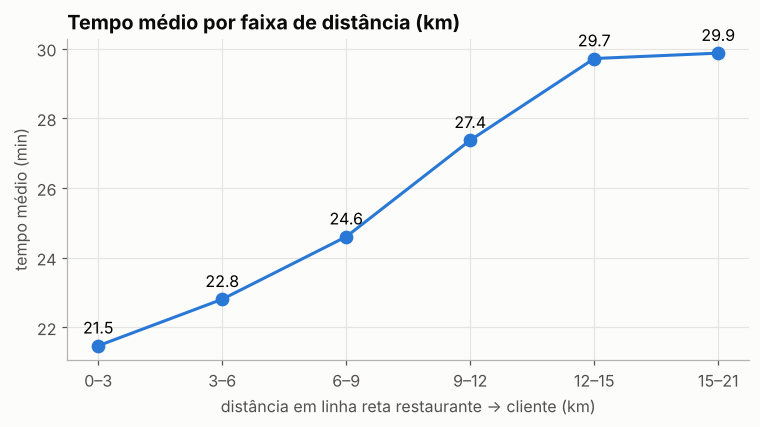

Spearman distância × tempo: 0.32


In [17]:
faixa_dist = pd.cut(df["distancia_km"], [0, 3, 6, 9, 12, 15, 21], labels=["0–3", "3–6", "6–9", "9–12", "12–15", "15–21"])
gd = df.groupby(faixa_dist, observed=True)[ALVO].agg(pedidos="count", media="mean",
                                                    pct_acima_sla=lambda s: (s > SLA_MIN).mean() * 100)
display(gd.round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(gd.index.astype(str), gd["media"], color=AZUL, lw=2, marker="o", ms=8)
for x, v in zip(gd.index.astype(str), gd["media"]):
    ax.annotate(f"{v:.1f}", (x, v), xytext=(0, 8), textcoords="offset points", ha="center")
ax.set_title("Tempo médio por faixa de distância (km)")
ax.set_ylabel("tempo médio (min)")
ax.set_xlabel("distância em linha reta restaurante → cliente (km)")
salvar(fig, "04_distancia")
plt.show()
print("Spearman distância × tempo:", round(stats.spearmanr(df["distancia_km"], df[ALVO], nan_policy="omit")[0], 3))

A distância importa, mas **menos do que se imagina**: de 0–3 km para 12–15 km o tempo sobe ~8 min, e depois **estabiliza**.
Como a distância é em linha reta e a base tem raio máximo de ~21 km, o mais provável é que a plataforma já limite o raio de atendimento — o ganho marginal de restringir ainda mais o raio é pequeno.

### 4.4 Entregas agrupadas (múltiplas entregas por viagem)

,pedidos,media,mediana,pct_acima_sla
entregas_multiplas,,,,
0,14057,22.90,22.00,18.10
1,28109,26.90,26.00,30.30
2,1982,40.50,40.00,100.00
3,361,47.80,48.00,100.00


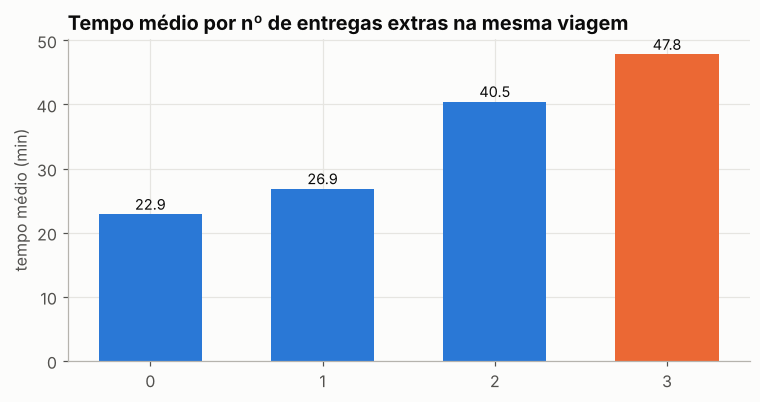

In [18]:
g = df.groupby("entregas_multiplas", observed=True)[ALVO].agg(pedidos="count", media="mean", mediana="median",
                                               pct_acima_sla=lambda s: (s > SLA_MIN).mean() * 100)
g = g.loc[[0, 1, 2, 3]]
display(g.round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
cores = [LARANJA if i == g.index.get_loc(3) else AZUL for i in range(len(g))]
ax.bar(g.index.astype(str), g['media'], color=cores, width=0.6)
rotular_barras(ax, horizontal=False)
ax.set_title("Tempo médio por nº de entregas extras na mesma viagem")
ax.set_ylabel('tempo médio (min)')

salvar(fig, "05_entregas_multiplas")
plt.show()

In [19]:
pv = df.pivot_table(index="transito", columns="entregas_multiplas", values=ALVO, aggfunc="mean", observed=True).round(1)
pv

entregas_multiplas,0,1,2,3
transito,,,,
Baixo,19.20,22.30,38.70,43.60
Médio,23.70,27.30,38.90,46.20
Alto,24.00,27.70,39.80,47.80
Congestionado,27.50,30.90,41.50,48.20


**Um dos maiores efeitos da base.** Agrupar 1 pedido extra custa ~4 min; com **2 ou 3 extras o tempo praticamente dobra** (de ~23 para 40–48 min) e **100%** desses pedidos estouram o SLA.
O efeito aparece em **todos** os níveis de trânsito — não é o trânsito disfarçado.
Agrupamento economiza custo de frota, mas acima de 1 pedido extra o custo em experiência é desproporcional.

### 4.5 Tempo de preparo (pedido → coleta)

In [20]:
print(df["tempo_preparo_min"].value_counts().sort_index())
print("\nSpearman preparo × tempo de entrega:", round(stats.spearmanr(df["tempo_preparo_min"], df[ALVO], nan_policy="omit")[0], 3))

tempo_preparo_min
5.00     14703
10.00    14549
15.00    14610
Name: count, dtype: int64

Spearman preparo × tempo de entrega: -0.007


O tempo entre pedido e coleta assume só 3 valores (5, 10 ou 15 min) e **não tem relação** com o tempo de entrega. Ou é um campo arredondado/estimado, ou o `Time_taken` mede apenas o trecho coleta → cliente.
Conclusão prática: com esses dados, **o gargalo está na rua, não na cozinha**.

## 5. Fatores externos

### 5.1 Clima

,pedidos,media,mediana,pct_acima_sla
clima,,,,
Ensolarado,7284,21.90,20.00,12.50
Tempestade,7586,25.90,26.00,25.50
Tempestade de areia,7495,25.90,26.00,26.00
Ventania,7422,26.10,26.00,26.60
Neblina,7654,28.90,28.00,43.80
Nublado,7536,28.90,28.00,43.80


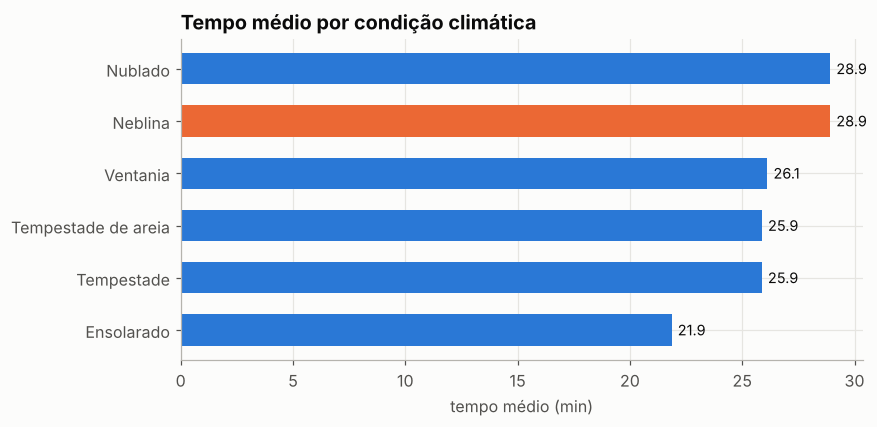

In [21]:
g = df.groupby("clima", observed=True)[ALVO].agg(pedidos="count", media="mean", mediana="median",
                                               pct_acima_sla=lambda s: (s > SLA_MIN).mean() * 100)
g = g.sort_values('media')
display(g.round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
cores = [LARANJA if i == g.index.get_loc('Neblina') else AZUL for i in range(len(g))]
ax.barh(g.index.astype(str), g['media'], color=cores, height=0.6)
rotular_barras(ax, horizontal=True)
ax.set_title("Tempo médio por condição climática")
ax.set_xlabel('tempo médio (min)')

salvar(fig, "06_clima")
plt.show()

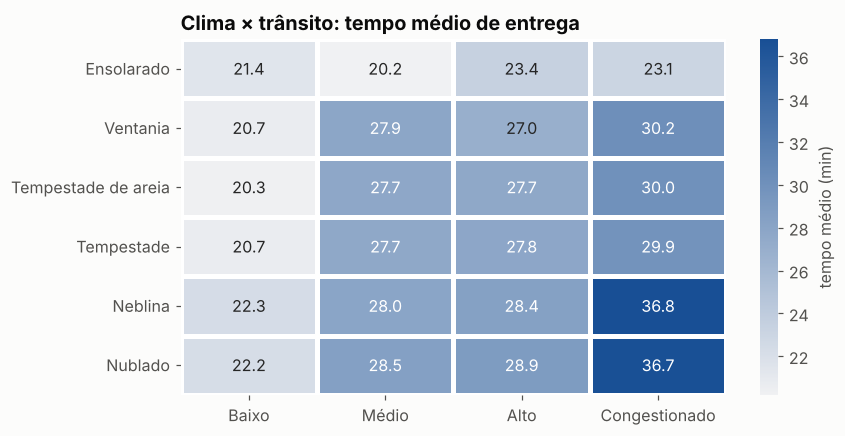

In [22]:
hm = df.pivot_table(index="clima", columns="transito", values=ALVO, aggfunc="mean", observed=True)
hm = hm.loc[hm.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(hm, annot=True, fmt=".1f", cmap=sns.light_palette(RAMPA_AZUL[-1], as_cmap=True),
            linewidths=2, linecolor="white", cbar_kws={"label": "tempo médio (min)"}, ax=ax)
ax.set_title("Clima × trânsito: tempo médio de entrega")
ax.set_xlabel("")
ax.set_ylabel("")
salvar(fig, "07_clima_transito")
plt.show()

- Dias **ensolarados** são ~7 min mais rápidos que dias de **neblina/nublados**.
- O clima **amplifica** o trânsito: neblina + congestionamento chega a ~37 min, enquanto sol + congestionamento fica em ~23 min.
- Tempestades e ventania ficam no meio do caminho — curiosamente, menos impactantes que neblina (visibilidade parece pesar mais que chuva).

### 5.2 Festivais

,pedidos,media,mediana,pct_acima_sla
festival,,,,
Não,44380,26.00,25.00,28.60
Sim,894,45.50,45.00,100.00


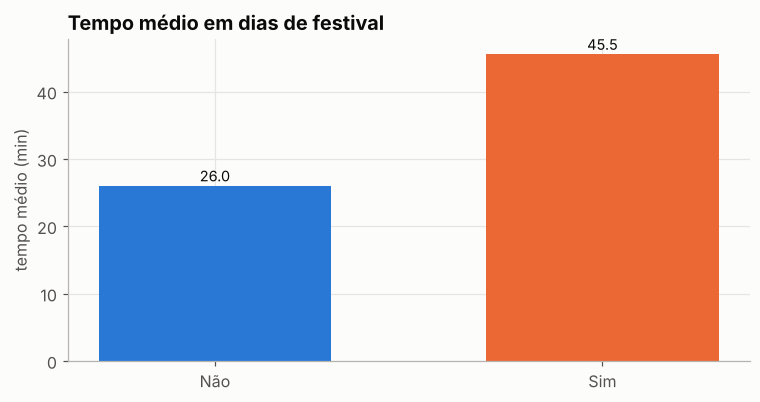

In [23]:
g = df.groupby("festival", observed=True)[ALVO].agg(pedidos="count", media="mean", mediana="median",
                                               pct_acima_sla=lambda s: (s > SLA_MIN).mean() * 100)
g = g.loc[['Não', 'Sim']]
display(g.round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
cores = [LARANJA if i == g.index.get_loc('Sim') else AZUL for i in range(len(g))]
ax.bar(g.index.astype(str), g['media'], color=cores, width=0.6)
rotular_barras(ax, horizontal=False)
ax.set_title("Tempo médio em dias de festival")
ax.set_ylabel('tempo médio (min)')

salvar(fig, "08_festival")
plt.show()

In [24]:
df.pivot_table(index="transito", columns="festival", values=ALVO, aggfunc="mean", observed=True).round(1)

festival,Não,Sim
transito,,
Baixo,21.30,42.00
Médio,26.60,43.70
Alto,27.00,45.80
Congestionado,30.50,46.10


**O maior efeito isolado da base:** em dias de festival, o tempo médio salta de ~26 para ~46 min (**+75%**) e **100%** dos pedidos ficam fora do SLA — inclusive com **trânsito baixo** (42 min).
Isso sugere que o gargalo nesses dias não é a rua, e sim a **falta de entregadores para a demanda**.
São só ~2% dos pedidos, mas são dias previsíveis no calendário: o problema é de planejamento, não de surpresa.

## 6. Frota: tipo e condição do veículo

In [25]:
display(pd.crosstab(df["tipo_veiculo"], df["condicao_veiculo"], margins=True, margins_name="total"))
df.groupby("tipo_veiculo")[ALVO].mean().round(1).sort_values()

condicao_veiculo,0,1,2,3,total
tipo_veiculo,,,,,
Bicicleta,0,0,0,53,53
Moto,15009,7583,3753,82,26427
Scooter,0,7447,7655,142,15244
Scooter elétrica,0,0,3626,152,3778
total,15009,15030,15034,429,45502


tipo_veiculo
Scooter elétrica   24.50
Scooter            24.50
Bicicleta          26.70
Moto               27.60
Name: tempo_entrega_min, dtype: float64

tipo_veiculo,Bicicleta,Moto,Scooter,Scooter elétrica
condicao_veiculo,,,,
0,NaN,30.10,NaN,NaN
1,NaN,24.30,24.40,NaN
2,NaN,24.40,24.50,24.40
3,26.70,27.50,26.00,27.40


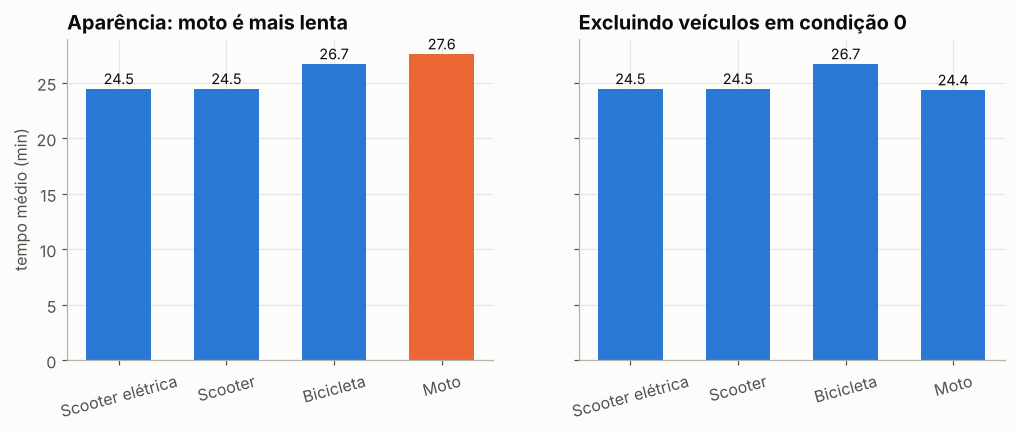

In [26]:
pv = df.pivot_table(index="condicao_veiculo", columns="tipo_veiculo", values=ALVO, aggfunc="mean").round(1)
display(pv)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
tv = df.groupby("tipo_veiculo")[ALVO].mean().sort_values()
axes[0].bar(tv.index, tv.values, color=[LARANJA if i == "Moto" else AZUL for i in tv.index], width=0.6)
rotular_barras(axes[0])
axes[0].set_title("Aparência: moto é mais lenta")
axes[0].set_ylabel("tempo médio (min)")

sem_cond0 = df[df["condicao_veiculo"] != 0].groupby("tipo_veiculo")[ALVO].mean().reindex(tv.index)
axes[1].bar(sem_cond0.index, sem_cond0.values, color=AZUL, width=0.6)
rotular_barras(axes[1])
axes[1].set_title("Excluindo veículos em condição 0")
for ax in axes:
    ax.tick_params(axis="x", rotation=15)
salvar(fig, "09_veiculo_confusao")
plt.show()

**Clássico caso de variável de confusão.** Olhando só o tipo, a moto parece ~3 min mais lenta que a scooter.
Mas **todos os veículos em condição 0 (pior estado) são motos** — e é a condição que causa a lentidão (~30 min contra ~24 min).
Comparando veículos na mesma condição, **moto, scooter e scooter elétrica empatam**.

**Conclusão:** a decisão certa não é trocar motos por scooters, e sim **tirar de circulação / reformar os veículos em pior estado**.

## 7. Entregadores: nota e idade

,pedidos,media
nota_entregador,,
"< 4,0",1329,37.10
"4,0–4,4",6695,34.60
"4,5–4,7",17385,24.20
"4,8–5,0",18185,24.40


,pedidos,media
idade_entregador,,
18–25,12956,23.00
26–30,10905,24.30
31–35,10937,29.70
36–39,8850,29.50


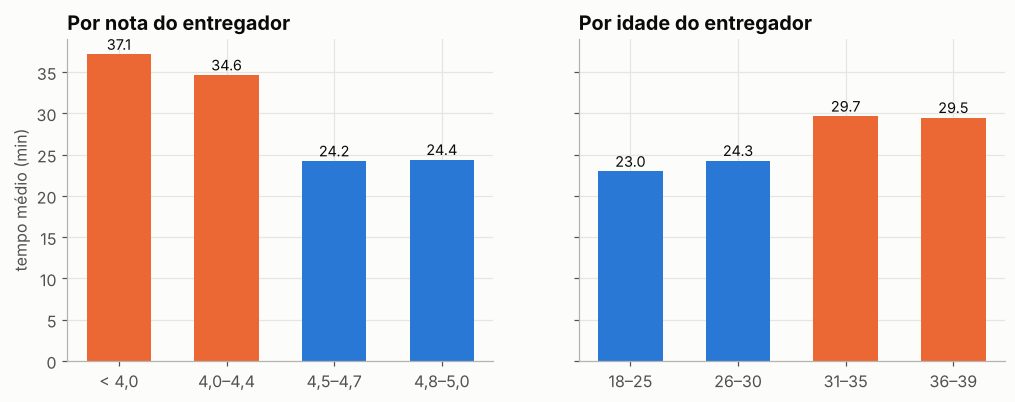

Correlação idade × nota: -0.118


In [27]:
faixa_nota = pd.cut(df["nota_entregador"], [0, 3.9, 4.4, 4.7, 5.0], labels=["< 4,0", "4,0–4,4", "4,5–4,7", "4,8–5,0"])
faixa_idade = pd.cut(df["idade_entregador"], [17, 25, 30, 35, 39], labels=["18–25", "26–30", "31–35", "36–39"])

gn = df.groupby(faixa_nota, observed=True)[ALVO].agg(pedidos="count", media="mean")
gi = df.groupby(faixa_idade, observed=True)[ALVO].agg(pedidos="count", media="mean")
display(gn.round(1), gi.round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
axes[0].bar(gn.index.astype(str), gn["media"], color=[LARANJA, LARANJA, AZUL, AZUL], width=0.6)
axes[0].set_title("Por nota do entregador")
axes[0].set_ylabel("tempo médio (min)")
axes[1].bar(gi.index.astype(str), gi["media"], color=[AZUL, AZUL, LARANJA, LARANJA], width=0.6)
axes[1].set_title("Por idade do entregador")
for ax in axes:
    rotular_barras(ax)
salvar(fig, "10_entregadores")
plt.show()
print("Correlação idade × nota:", round(df[["idade_entregador", "nota_entregador"]].corr().iloc[0, 1], 3))

- Entregadores com nota **abaixo de 4,5** levam ~10 min a mais (35–37 min contra ~24 min). A relação é um **degrau**, não uma rampa: acima de 4,5 a nota não diferencia mais ninguém.
- Entregadores com **mais de 30 anos** levam ~6 min a mais — também em formato de degrau.
- Idade e nota são quase independentes (correlação ≈ −0,12), então são dois efeitos distintos.

**Cuidado com a causalidade da nota:** a nota pode ser *consequência* de entregas lentas (clientes avaliam pior quem atrasa), não causa. Ela é um bom **sinal de alerta** para gestão da frota, mas não deve ser lida como "nota alta torna o entregador rápido".
O efeito idade pode refletir rotas, turnos ou veículos diferentes — não deve virar critério de contratação sem investigação adicional.

## 8. Geografia: cidade real × tipo de região

In [28]:
gc = df.groupby("cidade")[ALVO].agg(pedidos="count", media="mean").sort_values("media")
print(f"Amplitude entre cidades: {gc['media'].min():.1f} a {gc['media'].max():.1f} min")
display(gc.round(1).T)

bar_tipo = df.groupby("tipo_cidade")[ALVO].agg(pedidos="count", media="mean", mediana="median")
display(bar_tipo.round(1))
display(pd.crosstab(df["cidade"], df["tipo_cidade"], normalize="index").mul(100).round(0).head(6))

Amplitude entre cidades: 26.0 a 27.0 min


cidade,MYS,MUM,BANG,SUR,INDO,GOA,RANCHI,LUDH,VAD,COIMB,PUNE,KOC,KNP,KOL,CHEN,HYD,AURG,AGR,DEH,JAP,BHP,ALH
pedidos,3164.00,3168.00,3184.00,3182.00,3154.00,709.00,3222.00,758.00,3159.00,3162.00,3129.00,701.00,737.00,699.00,3132.00,3177.00,703.00,761.00,735.00,3439.00,689.00,738.00
media,26.00,26.00,26.10,26.10,26.10,26.20,26.20,26.30,26.30,26.30,26.30,26.30,26.40,26.40,26.40,26.40,26.60,26.70,26.70,26.70,26.80,27.00


,pedidos,media,mediana
tipo_cidade,,,
Metropolitana,34029,27.30,27.00
Semiurbana,164,49.70,49.00
Urbana,10111,23.00,22.00


tipo_cidade,Metropolitana,Semiurbana,Urbana
cidade,,,
AGR,77.00,0.00,23.00
ALH,77.00,0.00,23.00
AURG,76.00,0.00,24.00
BANG,76.00,0.00,23.00
BHP,81.00,0.00,19.00
CHEN,77.00,0.00,22.00


**Achado de qualidade de dado:** as 22 cidades têm tempos quase idênticos (26,0 a 27,0 min). Já o campo `City` (Metropolitana/Urbana/Semiurbana) separa bem: urbana ~23 min, metropolitana ~27 min, semiurbana ~50 min.

Mas **toda cidade aparece ~77% como "metropolitana" e ~23% como "urbana"** — Mumbai e Ranchi com a mesma proporção. Ou seja, `City` não descreve a cidade: provavelmente classifica a **zona** do cliente dentro dela.
O grupo semiurbano tem só 164 pedidos (0,4%), nenhum com trânsito baixo e 25% em festival — por isso o tempo extremo. Tamanho pequeno demais para conclusões firmes.

## 9. Testes estatísticos

O tempo de entrega não é normal (assimétrico), então usamos testes **não paramétricos**: Kruskal-Wallis para variáveis categóricas (com tamanho de efeito ε²) e Spearman para numéricas. Com 45 mil linhas, quase tudo dá p < 0,05 — por isso o **tamanho do efeito** é o que importa.

In [29]:
def kruskal(col):
    grupos = [g[ALVO].values for _, g in df.dropna(subset=[col]).groupby(col, observed=True)]
    h, p = stats.kruskal(*grupos)
    n = sum(len(g) for g in grupos)
    return h, p, h / (n - 1)

def forca(e2):
    return "grande" if e2 >= .14 else "média" if e2 >= .06 else "pequena" if e2 >= .01 else "desprezível"

linhas = []
for col in ["transito", "entregas_multiplas", "festival", "clima", "condicao_veiculo", "tipo_cidade",
            "tipo_veiculo", "tipo_pedido", "dia_semana", "cidade"]:
    h, p, e2 = kruskal(col)
    linhas.append({"variável": col, "teste": "Kruskal-Wallis", "estatística": h, "p-valor": p, "efeito": e2,
                   "métrica": "ε²", "força": forca(e2)})
for col in ["distancia_km", "nota_entregador", "idade_entregador", "tempo_preparo_min"]:
    r, p = stats.spearmanr(df[col], df[ALVO], nan_policy="omit")
    linhas.append({"variável": col, "teste": "Spearman", "estatística": r, "p-valor": p, "efeito": r ** 2,
                   "métrica": "ρ²", "força": forca(r ** 2)})

testes = pd.DataFrame(linhas).sort_values("efeito", ascending=False)
testes.style.format({"estatística": "{:.3f}", "p-valor": "{:.1e}", "efeito": "{:.3f}"})

,variável,teste,estatística,p-valor,efeito,métrica,força
0,transito,Kruskal-Wallis,8266.308,0.0e+00,0.184,ε²,grande
1,entregas_multiplas,Kruskal-Wallis,6913.291,0.0e+00,0.155,ε²,grande
10,distancia_km,Spearman,0.320,0.0e+00,0.102,ρ²,média
12,idade_entregador,Spearman,0.313,0.0e+00,0.098,ρ²,média
11,nota_entregador,Spearman,-0.295,0.0e+00,0.087,ρ²,média
4,condicao_veiculo,Kruskal-Wallis,3193.565,0.0e+00,0.070,ε²,média
3,clima,Kruskal-Wallis,2948.211,0.0e+00,0.066,ε²,média
5,tipo_cidade,Kruskal-Wallis,2262.363,0.0e+00,0.051,ε²,pequena
2,festival,Kruskal-Wallis,2287.466,0.0e+00,0.051,ε²,pequena
6,tipo_veiculo,Kruskal-Wallis,1077.070,3.4e-233,0.024,ε²,pequena


- **Efeito grande:** trânsito e entregas múltiplas.
- **Efeito médio:** distância, idade, nota, condição do veículo e clima.
- **Efeito pequeno:** zona (tipo de cidade), festival e tipo de veículo. O festival tem efeito enorme *por pedido*, mas atinge só 2% da base — por isso explica pouca variação no total.
- **Desprezível / não significativo:** dia da semana, **cidade**, **tipo de pedido** e tempo de preparo (os três últimos com p > 0,1). O que o cliente pede e em qual cidade mora não importam.

## 10. Análise multivariada: efeito isolado de cada fator

As seções anteriores comparam um fator por vez. Como os fatores se misturam (ex.: dias de festival também têm mais trânsito e mais agrupamento), uma **regressão linear (OLS)** separa quantos minutos cada fator adiciona **mantendo os demais constantes**. O objetivo é explicar, não prever.

In [30]:
base_ols = df.dropna(subset=["transito", "clima", "festival", "entregas_multiplas", "distancia_km",
                             "nota_entregador", "idade_entregador", "tipo_cidade"]).copy()
base_ols["transito"] = base_ols["transito"].astype(str)
base_ols["entregas_multiplas"] = base_ols["entregas_multiplas"].astype(int)
base_ols["condicao_veiculo"] = base_ols["condicao_veiculo"].astype(int)
base_ols["nota_abaixo_4_5"] = (base_ols["nota_entregador"] < 4.5).astype(int)
base_ols["idade_acima_30"] = (base_ols["idade_entregador"] > 30).astype(int)

formula = (f"{ALVO} ~ C(transito, Treatment('Baixo')) + C(clima, Treatment('Ensolarado'))"
           " + C(festival, Treatment('Não')) + C(entregas_multiplas) + C(condicao_veiculo, Treatment(1))"
           " + C(tipo_cidade, Treatment('Urbana')) + C(tipo_veiculo, Treatment('Moto'))"
           " + distancia_km + nota_abaixo_4_5 + idade_acima_30")
ols = smf.ols(formula, data=base_ols).fit()
print(f"n = {int(ols.nobs):,} | R² = {ols.rsquared:.3f} | R² ajustado = {ols.rsquared_adj:.3f}")

n = 38,064 | R² = 0.638 | R² ajustado = 0.638


,efeito_min,ic_inf,ic_sup,p
veículo: Scooter elétrica,-0.07,-0.32,0.18,0.60
condição do veículo: 2,0.07,-0.09,0.22,0.39
veículo: Scooter,0.12,-0.03,0.27,0.13
distância (+1 km),0.33,0.32,0.34,0.00
zona: Metropolitana,1.72,1.58,1.86,0.00
entregas extras: 1,1.78,1.65,1.90,0.00
clima: Tempestade,2.86,2.67,3.06,0.00
clima: Tempestade de areia,2.88,2.68,3.08,0.00
clima: Ventania,3.01,2.81,3.21,0.00
trânsito: Médio,3.95,3.79,4.10,0.00


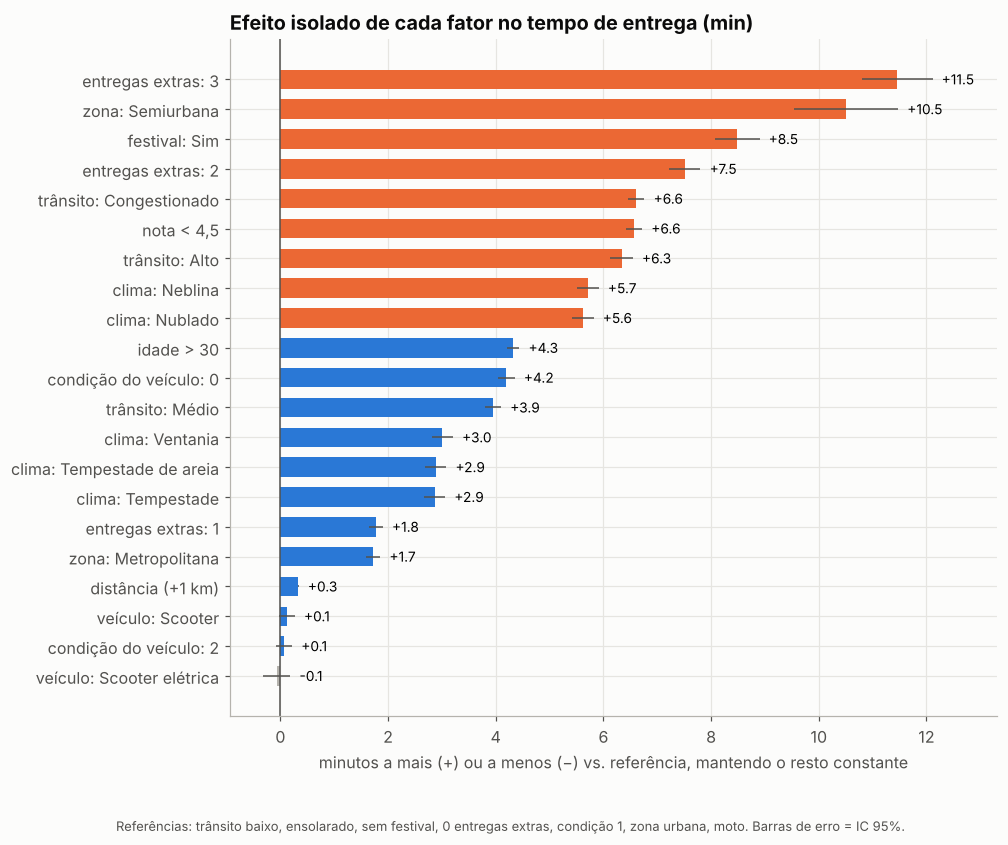

In [31]:
import re

def nome_legivel(termo):
    m = re.match(r"C\((\w+).*?\)\[T\.(.+)\]", termo)
    if m:
        return f"{m.group(1).replace('_', ' ')}: {m.group(2)}"
    return {"distancia_km": "distância (+1 km)", "nota_abaixo_4_5": "nota < 4,5",
            "idade_acima_30": "idade > 30"}.get(termo, termo)

ROTULOS = {"entregas multiplas": "entregas extras", "condicao veiculo": "condição do veículo",
           "transito": "trânsito", "tipo veiculo": "veículo", "tipo cidade": "zona"}

coef = pd.DataFrame({"efeito_min": ols.params, "ic_inf": ols.conf_int()[0], "ic_sup": ols.conf_int()[1],
                     "p": ols.pvalues}).drop("Intercept")
coef.index = [nome_legivel(i) for i in coef.index]
for a, b in ROTULOS.items():
    coef.index = coef.index.str.replace(a, b, regex=False)
coef = coef.sort_values("efeito_min")
display(coef.round(2))

fig, ax = plt.subplots(figsize=(9, 8))
cores = [LARANJA if v >= 5 else AZUL if v >= 0 else CINZA for v in coef["efeito_min"]]
ax.barh(coef.index, coef["efeito_min"], color=cores, height=0.65)
ax.errorbar(coef["efeito_min"], coef.index, xerr=[coef["efeito_min"] - coef["ic_inf"], coef["ic_sup"] - coef["efeito_min"]],
            fmt="none", ecolor=TEXTO_2, lw=1)
ax.axvline(0, color=TEXTO_2, lw=1)
for y, (v, sup) in enumerate(zip(coef["efeito_min"], coef["ic_sup"])):
    ax.annotate(f"{v:+.1f}", (max(sup, 0), y), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_xlim(right=coef["ic_sup"].max() + 1.2)
ax.set_title("Efeito isolado de cada fator no tempo de entrega (min)")
ax.set_xlabel("minutos a mais (+) ou a menos (−) vs. referência, mantendo o resto constante")
fig.text(0.01, -0.02, "Referências: trânsito baixo, ensolarado, sem festival, 0 entregas extras, condição 1, zona urbana, moto. Barras de erro = IC 95%.",
         fontsize=8.5, color=TEXTO_2)
salvar(fig, "11_efeitos_ols")
plt.show()

A regressão explica 64% da variação (R² = 0,64). Controlando por todos os outros fatores ao mesmo tempo:

- **3 entregas extras (+11,5 min)**, **2 extras (+7,5)** e **festival (+8,5)** são os maiores agravantes. No festival, o efeito isolado é menos da metade da diferença bruta (+20 min) — parte do atraso desses dias vem de mais agrupamento, pior trânsito e clima.
- **Zona semiurbana (+10,5)** pesa muito, mas tem o intervalo de confiança mais largo (só 164 pedidos).
- **Trânsito congestionado/alto (+6,3 a +6,6)**, **nota < 4,5 (+6,6)** e **neblina/nublado (+5,6 a +5,7)** formam o segundo bloco.
- **Idade > 30 (+4,3)** e **veículo em condição 0 (+4,2)** vêm em seguida.
- O **tipo de veículo** tem efeito zero (IC cruza o zero) quando a condição é controlada — confirmando o achado da seção 6.
- Cada km a mais custa só **~0,3 min**.

## 11. Conclusões

| # | Conclusão | Evidência |
|---|-----------|-----------|
| 1 | **30% dos pedidos estouram 30 min**; o pico de demanda (18h–23h) coincide com o pior trânsito | Seções 3 e 4.2 |
| 2 | **Festivais são o pior cenário**: +75% no tempo e 100% fora do SLA, mesmo com trânsito baixo → falta de capacidade, não de rua | Seção 5.2 |
| 3 | **Agrupar 2+ entregas extras quase dobra o tempo**, em qualquer nível de trânsito | Seção 4.4 |
| 4 | **A moto não é o problema — o veículo em mau estado é**. Na mesma condição, todos os veículos empatam | Seção 6 |
| 5 | **Neblina/nublado pesam mais que tempestade**, e o clima amplifica o efeito do trânsito | Seção 5.1 |
| 6 | **Entregadores com nota < 4,5 levam ~10 min a mais** — ótimo sinal de alerta (causalidade incerta) | Seção 7 |
| 7 | **O que o cliente pede e a cidade onde está não importam**; distância importa pouco | Seções 4.3, 8, 9 |
| 8 | **Isolando cada fator**, os maiores agravantes são entregas extras, festival e trânsito pesado; o tipo de veículo tem efeito zero | Seção 10 |

## Recomendações

1. **Calendário de festivais → plano de capacidade.** Reforçar a frota (incentivos, turnos extras) e ajustar a promessa de prazo nesses dias.
2. **Limitar agrupamento a no máximo 1 pedido extra** no horário de pico e em clima ruim; acima disso o ganho de custo não compensa o atraso.
3. **Programa de manutenção da frota:** priorizar a recuperação/substituição dos veículos em condição 0 em vez de trocar o tipo de veículo.
4. **Roteamento sensível a clima:** em neblina/nublado + trânsito pesado, reduzir o raio de entrega ou o agrupamento.
5. **Monitorar entregadores com nota < 4,5** com acompanhamento e treinamento (sem punição automática, dada a causalidade incerta).
6. **Prazo prometido por cenário:** em vez de um prazo fixo, ampliar a promessa ao cliente nos cenários críticos identificados (festival, 2+ entregas extras, neblina/nublado com trânsito pesado).

## Limitações

- **Indícios de dados semissintéticos:** o trânsito é quase determinado pela hora; idade e nota têm efeitos em "degrau"; o tempo de preparo só assume 3 valores; a proporção metropolitana/urbana é igual em todas as cidades. Os padrões são úteis para demonstrar o método, mas devem ser validados com dados reais antes de decisões.
- **Distância em linha reta** (Haversine), não a rota real.
- **Período curto** (fev–abr/2022): sem sazonalidade anual.
- **Análise observacional:** associações, não causalidade comprovada — especialmente para nota e idade.